# The spiking network

A ring of 2,048 excitatory and 512 inhibitory integrate-and-fire neurons with NMDA-only recurrent excitation (tau_NMDA = 150 ms) and a common input that dips and overshoots (`nmdaint/spiking.py`). Simulating one 2 s trial takes a few seconds per core.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, matplotlib.pyplot as plt
from nmdaint import spiking
net = spiking.Network(spiking.params())

## Trials with and without dips
Without dips the bump of activity persists at the cue; with dips it is silenced and reignites at the cued location when the input returns.

Text(0, 0.5, 'common input')

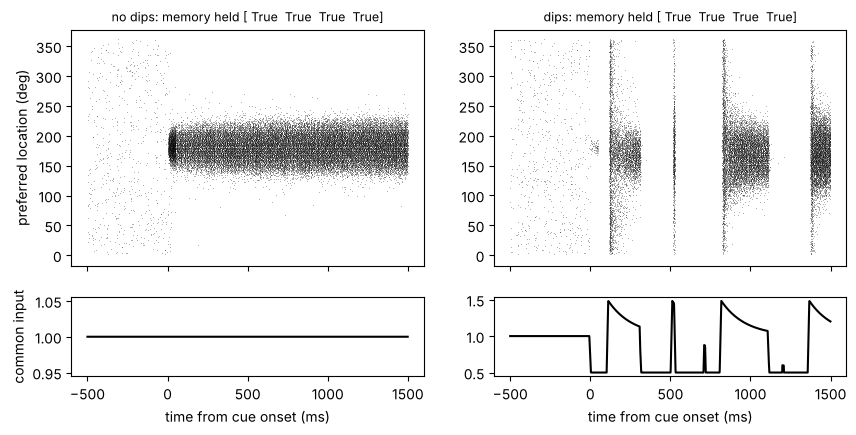

In [2]:
cues = [0, 90, 180, 270]          # deg
sims = {name: spiking.simulate(spiking.Network(spiking.params(dip_rate=rate)), cues, seed=1, raster=True)
        for name, rate in (('no dips', 1e-9), ('dips', 7.0))}
fig, ax = plt.subplots(2, 2, figsize=(10, 4.5), sharex=True, height_ratios=(3, 1))
for j, (name, sim) in enumerate(sims.items()):
    k = 2                             # the trial with the cue at 180 deg
    t, cell = np.nonzero(sim['raster'][k])
    ax[0, j].plot(sim['t1'][t], cell * 360 / net.p['N_E'], ',k', alpha=0.3)
    ax[0, j].set_title(f"{name}: memory held {spiking.memory(sim, net)}", fontsize=9)
    ax[1, j].plot(sim['t1'], sim['m_eff'][k], 'k')
    ax[1, j].set_xlabel('time from cue onset (ms)')
ax[0, 0].set_ylabel('preferred location (deg)'); ax[1, 0].set_ylabel('common input')

## Where is the bump?
Population-vector angle of the E spikes in 50 ms bins: it stays at the cue between silences.

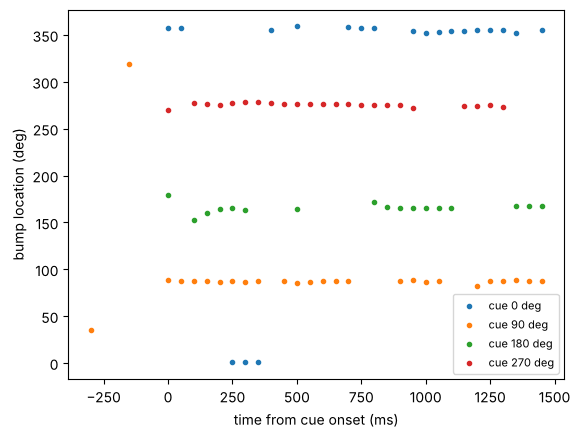

In [3]:
sim = sims['dips']
ras = sim['raster'].reshape(len(cues), -1, 50, net.p['N_E']).sum(2)          # 50 ms bins
vec = ras @ np.exp(1j * net.theta_E)
t50 = sim['t1'][::50]
for k, c in enumerate(cues):
    active = np.abs(vec[k]) > 20
    plt.plot(t50[active], np.rad2deg(np.angle(vec[k][active])) % 360, '.', label=f'cue {c} deg')
plt.xlabel('time from cue onset (ms)'); plt.ylabel('bump location (deg)'); plt.legend(fontsize=8)

## Read out like the data
Decoding needs whole sessions (480 trials, ~10 min each); the paper's example (Fig. 4a) is stored in `results/spiking/`. To run one: `d = spiking.session(net, 100, 0)` and `nmdaint.spiking_readout.read_session(d, seed=0)`.

Text(0, 0.5, 'decoding z (all units)')

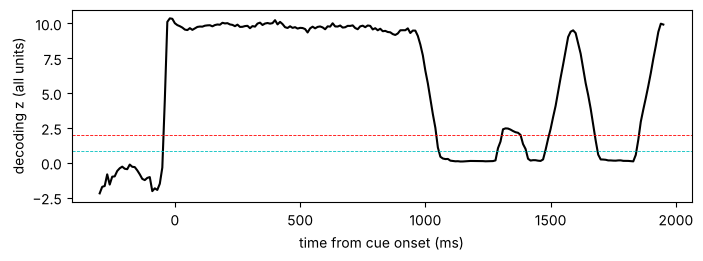

In [4]:
from nmdaint import paths
e = np.load(paths.results('spiking', 'example_trial.npz'))
plt.figure(figsize=(8, 2.5)); plt.plot(e['tz'], e['z'], 'k')
plt.axhline(1.96, color='r', ls='--', lw=0.6); plt.axhline(0.84, color='c', ls='--', lw=0.6)
plt.xlabel('time from cue onset (ms)'); plt.ylabel('decoding z (all units)')